Run MetaCell based on instruction on https://metacells.readthedocs.io/en/latest/readme.html

In [3]:
import metacells as mc
import scanpy as sc
import json
import os

RANDOM_SEED = 17
# SAMPLE_NAME = "egr_nextseq_batch1_rs17"
SAMPLE_NAME = "tung_batch1_rs17"
PATH_TEST_CONFIG = f"test/metacell/{SAMPLE_NAME}.json"
PATH_CELL_RANGER_BC_MATRIX = f"outputs/cellranger/reanalyze/{SAMPLE_NAME}/outs/filtered_feature_bc_matrix/"
PATH_CELL_COLOR = f"outputs/seurat_integration/barcode2color/{SAMPLE_NAME}.csv"
PATH_FIG_OUTPUT = f"test/metacell/{SAMPLE_NAME}.png"
DIR_OUTPUT = f"test/metacell/{SAMPLE_NAME}/"
os.makedirs(DIR_OUTPUT, exist_ok=True)


# Load Cell Ranger data
adata = sc.read_10x_mtx(
    PATH_CELL_RANGER_BC_MATRIX,
    var_names="gene_ids",  # or "gene_ids" if no symbols are available
    cache=True
)
mc.ut.set_name(adata=adata, name=SAMPLE_NAME)
# params
params = json.load(open(PATH_TEST_CONFIG))
print(params)

/home/b05b01002/Installed/miniconda3/envs/metacell/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'divide_and_conquer_pipeline': {'target_metacell_size': 50}, 'marker_gene_selection_method': 'find_high_normalized_variance_genes', 'distance_metric': 'euclidean', 'find_high_relative_variance_genes': {'min_gene_relative_variance': 0.1, 'inplace': False}, 'find_metacells_marker_genes': {'inplace': False}, 'find_high_normalized_variance_genes': {'min_gene_normalized_variance': 1, 'inplace': False}}


### MetaCell analysis of P. trichocarpa SDX cells  
As an alternative to unsupervised K-means clustering and UMAP visualization, the MetaCell package [55] (v0.3.41) was used to group the P. trichocarpa SDX cells and project them onto a two-dimensional plot. A total of 4278 variable genes were selected as marker genes (T_tot = 20, T_top3 = 1, T_szcor = −0.01, T_vm = 0.2, and T_niche = 0.05) for constructing k-nearest neighbor graphs with K = 40, followed by coclustering with bootstrapping based on 1000 iterations of resampling 75% of the cells and an approximated target minimum metacell size of 50. Unbalanced edges were filtered with K = 40 and alpha = 3. The individual cells were then plotted in a two-dimensional projection (Additional file 1: Fig. S18).

Currently the 1st step of the processing must be to create a “clean” data set which lacks the excluded genes and cells (e.g. using extract_clean_data).


In [4]:
# Do not exlucde any cells since they are already filtered by Cell Ranger
mc.pl.exclude_cells(
    adata,
    properly_sampled_min_cell_total=500,
    properly_sampled_max_cell_total=15000,
    properly_sampled_max_excluded_genes_fraction=None
)

set tung_batch1_rs17.obs[properly_sampled_cell]: 4745 true (97.63%) out of 4860 bools
set tung_batch1_rs17.obs[excluded_cell]: 115 true (2.366%) out of 4860 bools


Mark ```lateral_gene```

In [5]:
mc.pl.mark_lateral_genes(
    adata=adata,
    lateral_gene_names=None
)

set tung_batch1_rs17.var[lateral_gene]: 0 true (0%) out of 34699 bools


Mark ```noisy_gene```

In [6]:
mc.pl.mark_noisy_genes(
    adata=adata,
    noisy_gene_names=None
)

set tung_batch1_rs17.var[noisy_gene]: 0 true (0%) out of 34699 bools


- T_tot  
total down sampled coverage thresholds (genes with tot UMIs < T_tot are filtered out)  
  
- T_top3  
threshold value for the third highest umi count for the gene (genes with top3<T_top3 are filtered out)  
  
- T_szcor
threshold value for the normalized size correlation statistic (only genes with sz_cor < T_szcor are selected). If you use this, consider values around -0.1 - but evaluate carefully your decision using the gstat empirical data

- T_vm
the threshold value for the normalized var/mean (only genes with varmean > T_vm are selected) Recommended values are usually around 0.2, but this may vary with the data. Not recommended for datasets with hihgly heterogeneous cell sizes (e.g. in whole-organisms datasets)

- T_niche
threshold value for the normalized niche score statistic (only genes with niche_norm > T_niche are selected). Recommended to use in combination with szcor to add genes with strongly restricted expression patterns. Consider using values around 0.05

T_tot = 20, T_top3 = 1, T_szcor = −0.01, T_vm = 0.2, and T_niche = 0.05

In [7]:
mc.pl.set_max_parallel_piles(20)
mc.pl.divide_and_conquer_pipeline(
    adata=adata,
    random_seed=RANDOM_SEED,
    **params["divide_and_conquer_pipeline"]
)

set tung_batch1_rs17.var[selected_gene]: * -> False
set tung_batch1_rs17.var[rare_gene]: 0 true (0%) out of 34699 bools
set tung_batch1_rs17.var[rare_gene_module]: 34699 int32 elements with all outliers (100%)
set tung_batch1_rs17.obs[cells_rare_gene_module]: 4860 int32 elements with all outliers (100%)
set tung_batch1_rs17.obs[rare_cell]: 0 true (0%) out of 4860 bools
set tung_batch1_rs17.var[selected_gene]: 936 true (2.697%) out of 34699 bools
set tung_batch1_rs17.obs[metacell]: 4860 int32s
set tung_batch1_rs17.obs[dissolved]: 1 true (0.02058%) out of 4860 bools
set tung_batch1_rs17.obs[metacell_level]: 4860 int32s


In [8]:
gdata = mc.pl.collect_metacells(
    adata=adata,
    random_seed=RANDOM_SEED
)
print(f"Preliminary: {gdata.n_obs} metacells, {gdata.n_vars} genes")

set metacells.obs[grouped]: 110 int64s
set metacells.obs[total_umis]: 110 int64s
set metacells.layers[total_umis]: ndarray 110 X 34699 float32s
set metacells.obs[__zeros_downsample_umis]: 110 int64s
set metacells.layers[zeros]: ndarray 110 X 34699 int32s
set tung_batch1_rs17.obs[metacell_name]: 4860 <U8s
set metacells.var[gene_symbols]: 34699 objects
set metacells.var[feature_types]: 34699 objects
set metacells.var[lateral_gene]: 0 true (0%) out of 34699 bools
set metacells.var[noisy_gene]: 0 true (0%) out of 34699 bools
set metacells.var[selected_gene]: 936 true (2.697%) out of 34699 bools
set metacells.var[rare_gene]: 0 true (0%) out of 34699 bools
set metacells.var[rare_gene_module]: 34699 int32s
set metacells.obs[metacells_rare_gene_module]: 110 int32s
set metacells.obs[rare_metacell]: 0 true (0%) out of 110 bools
set metacells.uns[outliers]: 166
set metacells.uns[metacells_algorithm]: metacells.0.9.5


Preliminary: 110 metacells, 34699 genes


Heatmap representation of metacells difference in metacell marker gene expression

In [9]:
# reload params
params = json.load(open(PATH_TEST_CONFIG))

# function dict
function_dict = {
    "find_high_relative_variance_genes": mc.tl.find_high_relative_variance_genes,
    "find_metacells_marker_genes": mc.tl.find_metacells_marker_genes,
    "find_high_normalized_variance_genes": mc.tl.find_high_normalized_variance_genes,
}

# marker gene selection
method = params["marker_gene_selection_method"]
metacell_marker_genes = function_dict[method](adata=gdata, **params[method])
metacell_marker_gene_names = metacell_marker_genes[metacell_marker_genes].index
print(f"Marker genes: {len(metacell_marker_gene_names)}")
metacell_marker_gene_names

Marker genes: 5245


Index(['Potri.001G000500.v4.1', 'Potri.001G001000.v4.1',
       'Potri.001G001201.v4.1', 'Potri.001G001250.v4.1',
       'Potri.001G003000.v4.1', 'Potri.001G003632.v4.1',
       'Potri.001G004366.v4.1', 'Potri.001G004432.v4.1',
       'Potri.001G004900.v4.1', 'Potri.001G006000.v4.1',
       ...
       'Potri.T127106.v4.1', 'Potri.T124607.v4.1', 'Potri.T125407.v4.1',
       'Potri.T124308.v4.1', 'Potri.T124408.v4.1', 'Potri.T124608.v4.1',
       'Potri.T124708.v4.1', 'Potri.T124808.v4.1', 'Potri.T125308.v4.1',
       'Potri.T125408.v4.1'],
      dtype='object', length=5245)

In [10]:
from scipy.spatial import distance
import pandas as pd

# Get mark gene expression matrix
metacells_mark_genes_mtx = mc.ut.get_vo_frame(
    adata=gdata,
)[metacell_marker_gene_names]

# Calculate pairwise distance between metacells (euclidean distance; metacells as rows)
metacells_distance = distance.squareform(
    distance.pdist(
        metacells_mark_genes_mtx,
        metric=params["distance_metric"]
))

metacells_distance_df = pd.DataFrame(
    metacells_distance,
    index=gdata.obs_names,
    columns=gdata.obs_names
)

metacells_distance_df

,M0.15,M1.28,M2.01,M3.31,M4.92,M5.87,M6.23,M7.40,M8.45,M9.88,...,M100.22,M101.95,M102.81,M103.26,M104.93,M105.49,M106.62,M107.38,M108.69,M109.50
M0.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M1.28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M2.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M3.31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M4.92,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
M105.49,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M106.62,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M107.38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
M108.69,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Get cell color and transfer color to metacells

In [11]:
# get cell color
PATH_CELL_COLOR = f"outputs/seurat_integration/barcode2color/{SAMPLE_NAME}.csv"
cell_color = pd.read_csv(PATH_CELL_COLOR, index_col=0)
cell_color

# get metacell assignment from adata
cell_color = cell_color.merge(
    adata.obs["metacell_name"],
    left_index=True,
    right_index=True
)


# get the highest ratio Cluster by metacells
def get_max_cluster(x):
    ratio = x["Cluster"].value_counts() / x.shape[0]
    out = x.iloc[ratio.idxmax()][["Cluster", "Color"]]
    out["ratio"] = ratio.max()
    return out

metacell_color = cell_color.groupby("metacell_name").apply(get_max_cluster)
metacell_color = metacell_color.sort_values(by=["Cluster", "ratio"], ascending=[True, False])
metacell_color = metacell_color[metacell_color.index != "Outliers"]
metacell_color.to_csv(f"{DIR_OUTPUT}/metacell_color.csv")

/tmp/ipykernel_523668/2411054194.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metacell_color = cell_color.groupby("metacell_name").apply(get_max_cluster)


In [16]:
metacell_compo.reset_index()

,metacell_name,Cluster,count
0,M0.15,1,0.720930
1,M0.15,2,0.232558
2,M0.15,5,0.046512
3,M1.28,4,0.593220
4,M1.28,5,0.406780
...,...,...,...
246,Outliers,5,0.042169
247,Outliers,8,0.012048
248,Outliers,1,0.012048
249,Outliers,7,0.006024


/tmp/ipykernel_523668/941215261.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metacell_compo = cell_color.groupby("metacell_name").apply(lambda x: x["Cluster"].value_counts() / x.shape[0])


<Axes: xlabel='metacell_name', ylabel='Cluster'>

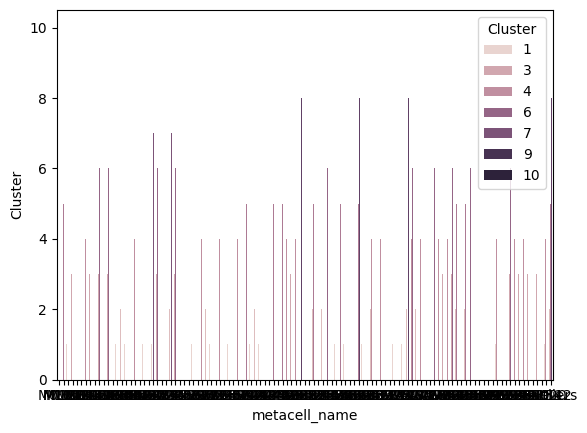

In [ ]:
metacell_compo = cell_color.groupby("metacell_name").apply(lambda x: x["Cluster"].value_counts() / x.shape[0])
metacell_compo = metacell_compo.reset_index()
metacell_compo.to_csv(f"{DIR_OUTPUT}/metacell_compo.csv")
# plot
import seaborn as sns
sns.barplot(metacell_compo, x = "metacell_name", y = "Cluster")

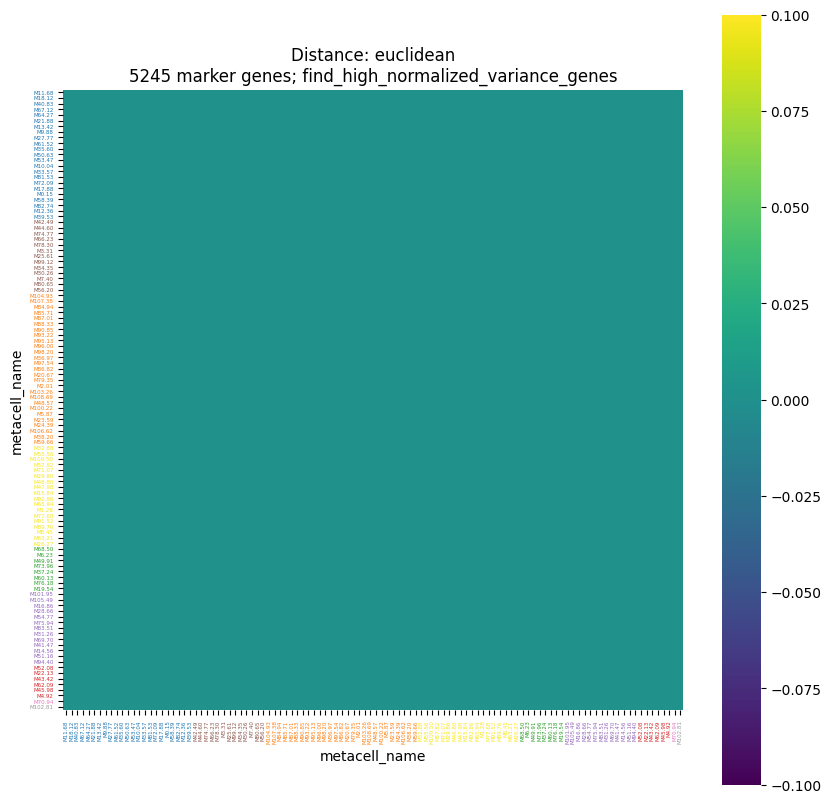

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(
    metacells_distance_df.loc[metacell_color.index, metacell_color.index],
    ax=ax,
    cmap="viridis",
    square=True,
    xticklabels=True, 
    yticklabels=True
)
for i, tick_label in enumerate(ax.axes.get_yticklabels()):
    tick_label.set_color(
        metacell_color.loc[tick_label._text, "Color"]
    )
    tick_label.set_fontsize(4)
for i, tick_label in enumerate(ax.axes.get_xticklabels()):
    tick_label.set_color(
        metacell_color.loc[tick_label._text, "Color"]
    )
    tick_label.set_fontsize(4)
    
# titles
ax.set_title(
    f"Distance: {params['distance_metric']}\n{len(metacell_marker_gene_names)} marker genes; {params['marker_gene_selection_method']}",
    fontsize=12
)
fig.savefig(
    DIR_OUTPUT + 
    params["marker_gene_selection_method"] + "_" +
    params["distance_metric"] +
    ".png",
    dpi=300
)

In [ ]:
# with mc.ut.progress_bar():
#     mc.pl.compute_for_mcview(
#         adata=adata,
#         gdata=gdata,
#         random_seed=RANDOM_SEED
#     )

In [ ]:
# import matplotlib.pyplot as plt
# import scipy.sparse as sp
# import seaborn as sns
# from math import hypot

# min_long_edge_size = 4
# umap_x = mc.ut.get_o_numpy(gdata, "x")
# umap_y = mc.ut.get_o_numpy(gdata, "y")
# umap_edges = sp.coo_matrix(mc.ut.get_oo_proper(gdata, "obs_outgoing_weights"))
# # sns.set()
# plot = sns.scatterplot(x=umap_x, y=umap_y, s=10)
# # for (
# #     source_index, target_index, weight
# # ) in zip(
# #     umap_edges.row, umap_edges.col, umap_edges.data
# # ):
# #     source_x = umap_x[source_index]
# #     target_x = umap_x[target_index]
# #     source_y = umap_y[source_index]
# #     target_y = umap_y[target_index]
# #     if hypot(target_x - source_x, target_y - source_y) >= min_long_edge_size:
# #         plt.plot([source_x, target_x], [source_y, target_y],
# #                  linewidth=weight * 2, color='indigo')
# plt.show()


Find marker genes and compute UMAP by marker genes

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd
# import numpy as np

# # reload params
# params = json.load(open(PATH_TEST_CONFIG))

# # find marker genes
# print("Finding marker genes")
# metacell_marker_genes = mc.tl.find_high_relative_variance_genes(
#     adata=gdata,
#     inplace=False,
#     **params["find_high_relative_variance_genes"]
# )
# # metacell_marker_genes = mc.tl.find_metacells_marker_genes(
# #     adata=gdata,
# #     inplace=False
# # )
# marker_gene_names = metacell_marker_genes[metacell_marker_genes].index
# # marker_gene_names = gdata.var[gdata.var["selected_gene"]].index
# print(f"Found {len(marker_gene_names)} marker genes")

# # compute UMAP by marker genes
# print("Computing UMAP by marker genes")
# mc.pl.compute_umap_by_markers(
#     adata=adata,
#     marker_gene_names=marker_gene_names,
#     random_seed=RANDOM_SEED
# )

# # get observation data
# obs = adata.obs.copy()

# # pre-defined cell colors
# colors = pd.read_csv(PATH_CELL_COLOR, index_col=0)
# palette = dict(zip(colors["Cluster"], colors["Color"]))
# palette

# # merge colors to obs
# obs = obs.merge(colors, left_index=True, right_index=True)

# # plot
# # create figure
# fig, ax = plt.subplots(figsize=(27, 18))
# sns.scatterplot(
#     x="x",
#     y="y",
#     hue="Cluster",
#     data=obs,
#     palette=palette,
#     ax=ax
# )

# # figure title
# plt.title(f"{SAMPLE_NAME}")

# # save figure
# fig.savefig(PATH_FIG_OUTPUT)


Find marker genes and compute UMAP by marker genes

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd
# import numpy as np

# # find marker genes
# marker_genes = mc.tl.find_high_normalized_variance_genes(
#     adata=adata,
#     inplace=False
# )
# marker_gene_names = marker_genes[marker_genes].index
# print(f"Found {len(marker_gene_names)} marker genes")

# if len(marker_gene_names) < 1000:
#     n_target_marker_genes = 1000
#     n_last_marker_genes = 0
#     for min_gene_normalized_variance in np.linspace(1, 10, 200): 
#         marker_genes = mc.tl.find_high_normalized_variance_genes(
#             adata=adata,
#             min_gene_normalized_variance=min_gene_normalized_variance,
#             inplace=False
#         )
#         n_marker_genes = sum(marker_genes)
#         if abs(n_marker_genes - n_target_marker_genes) \
#             < abs(n_last_marker_genes - n_target_marker_genes):
#             n_last_marker_genes = n_marker_genes
#             marker_gene_names = marker_genes[marker_genes].index
#     print(f"Rerun and found {len(marker_gene_names)} marker genes")


# # compute UMAP by marker genes
# mc.pl.compute_umap_by_markers(
#     adata=adata,
#     marker_gene_names=marker_gene_names,
#     random_seed=RANDOM_SEED
# )

# # get observation data
# obs = adata.obs.copy()

# # pre-defined cell colors
# colors = pd.read_csv(PATH_CELL_COLOR, index_col=0)
# palette = dict(zip(colors["Cluster"], colors["Color"]))
# palette

# # merge colors to obs
# obs = obs.merge(colors, left_index=True, right_index=True)

# # plot
# # create figure
# fig, ax = plt.subplots(figsize=(27, 18))
# sns.scatterplot(
#     x="x",
#     y="y",
#     hue="Cluster",
#     data=obs,
#     palette=palette,
#     ax=ax
# )

# # figure title
# plt.title(f"{SAMPLE_NAME} high normalized variance genes UMAP\n{len(marker_gene_names)} marker genes")

# # save figure
# fig.savefig(PATH_FIG_OUTPUT)
